# 4. Tutorial 4

**Course:** High Switching Frequency Power Converters

## 4.1 Damping of the gate loop

High-side switch EPC2045: $C_\mathrm{iss} = 737~\mathrm{pF}$, $Q_\mathrm{G} = 5.9~\mathrm{nC}$ at $5~\mathrm{V}$, $Q_\mathrm{GD} = 0.8~\mathrm{nC}$, $R_\mathrm{G,int} = 0.6~\Omega$, $V_\mathrm{th} = 1.4~\mathrm{V}$, gate limits $+6~\mathrm{V}$ and $-4~\mathrm{V}$. Driver: $V_\mathrm{dr} = 5~\mathrm{V}$, $R_\mathrm{up} = 2.1~\Omega$, $R_\mathrm{dn} = 0.6~\Omega$. Gate-loop inductance $L_\mathrm{G,on} = 2.0~\mathrm{nH}$, $L_\mathrm{G,off} = 1.2~\mathrm{nH}$.

4.1.1 Import necessary modules (numpy as np, matplotlib.pyplot as plt, scipy.signal, scipy.integrate.solve_ivp) and add the device and driver data as variables.

4.1.2 Create the functions
- `get_R_crit(L, C)`: total resistance for critical damping $2\sqrt{L/C}$,
- `get_zeta(R, L, C)`: damping ratio $\frac{R}{2}\sqrt{C/L}$,
- `get_step(R, L, C, V, t)`: step response of the series $RLC$ gate loop to a voltage step $V$ (use `scipy.signal.step`).

Print the minimum external gate resistance for critical damping at turn-on, once with $C_\mathrm{iss}$ and once with $Q_\mathrm{G}/V_\mathrm{dr}$.

4.1.3 Plot $v_\mathrm{GS}(t)$ at turn-on for $R_\mathrm{G,ext} = 0$, $0.68$ and $3.3~\Omega$ and at turn-off (from $5~\mathrm{V}$ to $0~\mathrm{V}$, $R_\mathrm{G,ext,off} = 0$), together with the gate limits and $V_\mathrm{th}$. Print the extreme values.

4.1.4 Plot the average switch-node $\mathrm{d}v/\mathrm{d}t$ at turn-on, $V_\mathrm{DC}(V_\mathrm{dr} - V_\mathrm{pl})/(R_\mathrm{G,on} Q_\mathrm{GD})$ with $V_\mathrm{pl} = 2.5~\mathrm{V}$ and $V_\mathrm{DC} = 48~\mathrm{V}$, versus $R_\mathrm{G,ext}$ in the range [$0 \ldots 6~\Omega$] and mark $50~\mathrm{V/ns}$ and $25~\mathrm{V/ns}$.


In [1]:
# Subtask 4.1.1 Import necessary modules and add the device and driver data.
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.integrate import solve_ivp

C_iss, Q_G, Q_GD, R_G_int = 737e-12, 5.9e-9, 0.8e-9, 0.6   # Unit F, C, C, Ohm (EPC2045)
V_th, V_GS_max, V_GS_min = 1.4, 6.0, -4.0                   # Unit V
V_dr, R_up, R_dn = 5.0, 2.1, 0.6                            # Unit V, Ohm, Ohm (driver)
L_G_on, L_G_off = 2.0e-9, 1.2e-9                            # Unit H
V_DC, I_L, V_pl = 48.0, 10.0, 2.5                           # Unit V, A, V


# Subtask 4.1.2 Damping of a series RLC gate loop
def get_R_crit(L, C):
    """Total loop resistance in Ohm for critical damping."""
    return 2 * np.sqrt(L / C)


def get_zeta(R, L, C):
    """Damping ratio of the series RLC loop."""
    return R / 2 * np.sqrt(C / L)


def get_step(R, L, C, V, t):
    """Voltage across C for a voltage step V applied to the series RLC loop."""
    _, y = signal.step(signal.TransferFunction([1], [L * C, R * C, 1]), T=t)
    return V * y


for C, name in [(C_iss, 'C_iss'), (Q_G / V_dr, 'Q_G/V_dr')]:
    R_crit = get_R_crit(L_G_on, C)
    print(f"{name} = {C*1e12:.0f} pF: R_crit = {R_crit:.2f} Ohm, R_G,ext >= {R_crit - R_up - R_G_int:.2f} Ohm")


C_iss = 737 pF: R_crit = 3.29 Ohm, R_G,ext >= 0.59 Ohm
Q_G/V_dr = 1180 pF: R_crit = 2.60 Ohm, R_G,ext >= -0.10 Ohm


turn-on, R_G,ext = 0 Ohm: zeta = 0.82, peak 5.06 V
turn-on, R_G,ext = 0.68 Ohm: zeta = 1.03, peak 5.00 V
turn-on, R_G,ext = 3.3 Ohm: zeta = 1.82, peak 4.86 V
turn-off: zeta = 0.47, minimum -0.94 V, next maximum 0.18 V


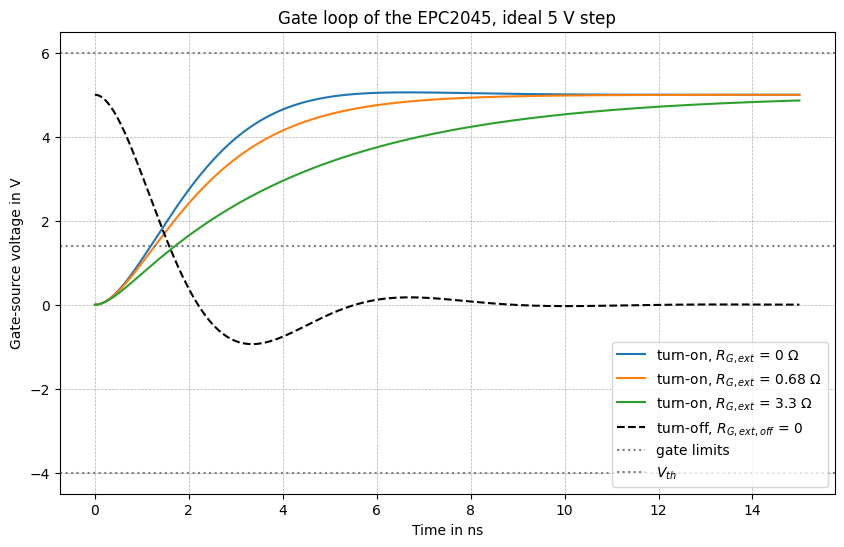

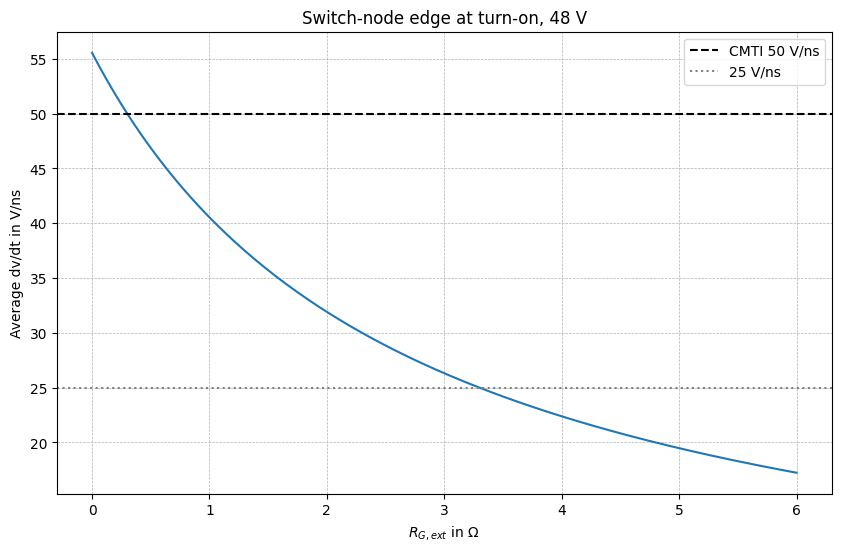

In [2]:
if __name__ == "__main__":
    # Subtask 4.1.3 Turn-on and turn-off of the gate
    t = np.linspace(0, 15e-9, 3001)
    plt.figure(figsize=(10, 6))
    for R_ext in [0, 0.68, 3.3]:
        R_on = R_up + R_G_int + R_ext
        v = get_step(R_on, L_G_on, C_iss, V_dr, t)
        print(f"turn-on, R_G,ext = {R_ext} Ohm: zeta = {get_zeta(R_on, L_G_on, C_iss):.2f}, peak {v.max():.2f} V")
        plt.plot(t * 1e9, v, label=f'turn-on, $R_{{G,ext}}$ = {R_ext} $\\Omega$')
    R_off = R_dn + R_G_int
    v_off = V_dr - get_step(R_off, L_G_off, C_iss, V_dr, t)
    k = np.argmin(v_off)
    print(f"turn-off: zeta = {get_zeta(R_off, L_G_off, C_iss):.2f}, minimum {v_off.min():.2f} V, "
          f"next maximum {v_off[k:].max():.2f} V")
    plt.plot(t * 1e9, v_off, 'k--', label='turn-off, $R_{G,ext,off}$ = 0')
    for level, text in [(V_GS_max, 'gate limits'), (V_GS_min, None), (V_th, '$V_{th}$')]:
        plt.axhline(level, color='gray', linestyle=':', label=text)
    plt.xlabel('Time in ns')
    plt.ylabel('Gate-source voltage in V')
    plt.title('Gate loop of the EPC2045, ideal 5 V step')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.show()

    # Subtask 4.1.4 Average dv/dt of the switch node at turn-on
    R_ext = np.linspace(0, 6, 200)
    dvdt = V_DC * (V_dr - V_pl) / ((R_up + R_G_int + R_ext) * Q_GD)
    plt.figure(figsize=(10, 6))
    plt.plot(R_ext, dvdt / 1e9)
    plt.axhline(50, color='k', linestyle='--', label='CMTI 50 V/ns')
    plt.axhline(25, color='gray', linestyle=':', label='25 V/ns')
    plt.xlabel('$R_{G,ext}$ in $\\Omega$')
    plt.ylabel('Average dv/dt in V/ns')
    plt.title('Switch-node edge at turn-on, 48 V')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.show()


### 4.1.4 Solution

With $C_\mathrm{iss}$ the critical resistance is $3.29~\Omega$, so $R_\mathrm{G,ext} \geq 0.59~\Omega$ (chosen $0.68~\Omega$); with $Q_\mathrm{G}/V_\mathrm{dr}$ only $2.60~\Omega$, i.e. no external resistor. The smaller capacitance is the conservative value. Without external resistor $\zeta = 0.82$ and the gate overshoots by only 1 % ($5.06~\mathrm{V}$); with $0.68~\Omega$ it stays at $5~\mathrm{V}$, with $3.3~\Omega$ the rise is slower. The turn-off loop ($\zeta = 0.47$) undershoots to $-0.94~\mathrm{V}$ and rings back to $0.18~\mathrm{V}$: no external turn-off resistor is needed. The average $\mathrm{d}v/\mathrm{d}t$ is $44~\mathrm{V/ns}$ with $0.68~\Omega$, too close to a CMTI of $50~\mathrm{V/ns}$; $25~\mathrm{V/ns}$ needs $R_\mathrm{G,ext} \approx 3.3~\Omega$.


## 4.2 Common-source inductance and turn-on loss

Hard turn-on at $V_\mathrm{DC} = 48~\mathrm{V}$, $I_\mathrm{L} = 10~\mathrm{A}$, $R_\mathrm{G} = 3.38~\Omega$, $g_\mathrm{m} = 9.1~\mathrm{S}$, $V_\mathrm{pl} = 2.5~\mathrm{V}$.

4.2.1 Create the function `get_t_ir(R_G, L_CS)` for the current-rise time $t_\mathrm{ir} = (R_\mathrm{G} C_\mathrm{iss} + L_\mathrm{CS} g_\mathrm{m}) \ln\frac{V_\mathrm{dr} - V_\mathrm{th}}{V_\mathrm{dr} - V_\mathrm{pl}}$ and print $t_\mathrm{ir}$ and $E_\mathrm{ir} = \frac{1}{2} V_\mathrm{DC} I_\mathrm{L} t_\mathrm{ir}$ for $L_\mathrm{CS} = 0$, $0.3$ and $1~\mathrm{nH}$.

4.2.2 Check the result with a simulation that includes the gate-loop inductance $L_\mathrm{G} = 2~\mathrm{nH}$: states $v_\mathrm{GS}$ and $i_\mathrm{G}$, $L_\mathrm{G}\,\mathrm{d}i_\mathrm{G}/\mathrm{d}t = V_\mathrm{dr} - R_\mathrm{G} i_\mathrm{G} - v_\mathrm{GS} - L_\mathrm{CS} g_\mathrm{m} i_\mathrm{G}/C_\mathrm{iss}$ (last term only for $v_\mathrm{GS} > V_\mathrm{th}$). Measure the time from $V_\mathrm{th}$ to $V_\mathrm{pl}$.

4.2.3 Plot $t_\mathrm{ir}$ and the loss $E_\mathrm{ir} f_\mathrm{sw}$ at $2~\mathrm{MHz}$ versus $L_\mathrm{CS}$ in the range [$0 \ldots 1.5~\mathrm{nH}$].


In [3]:
# Subtask 4.2.1 Current-rise time with common-source inductance
g_m, R_G = 9.1, 3.38   # Unit S, Ohm


def get_t_ir(R_G, L_CS):
    """Current-rise time in s from V_th to V_pl (first-order model, L_G neglected)."""
    tau = R_G * C_iss + L_CS * g_m
    return tau * np.log((V_dr - V_th) / (V_dr - V_pl))


for L_CS in [0, 0.3e-9, 1e-9]:
    t_ir = get_t_ir(R_G, L_CS)
    E_ir = 0.5 * V_DC * I_L * t_ir
    print(f"L_CS = {L_CS*1e9:.1f} nH: t_ir = {t_ir*1e9:.2f} ns, E_ir = {E_ir*1e6:.2f} uJ, "
          f"extra gate resistance {L_CS*g_m/C_iss:.1f} Ohm")


# Subtask 4.2.2 Simulation including the gate-loop inductance
def get_t_ir_sim(R_G, L_CS, L_G=2e-9):
    """Time in s from V_th to V_pl for the gate loop with L_G and L_CS."""
    def rhs(t, y):
        v, i = y
        k = L_CS * g_m / C_iss if v > V_th else 0.0
        return [i / C_iss, (V_dr - R_G * i - v - k * i) / L_G]

    def reach(level):
        ev = lambda t, y: y[0] - level
        ev.terminal, ev.direction = True, 1
        sol = solve_ivp(rhs, [0, 100e-9], [0.0, 0.0], events=ev, max_step=5e-12, rtol=1e-8, atol=1e-12)
        return sol.t_events[0][0]
    return reach(V_pl) - reach(V_th)


for L_CS in [0, 0.3e-9, 1e-9]:
    print(f"L_CS = {L_CS*1e9:.1f} nH: simulated t_ir = {get_t_ir_sim(R_G, L_CS)*1e9:.2f} ns "
          f"(first-order model {get_t_ir(R_G, L_CS)*1e9:.2f} ns)")


L_CS = 0.0 nH: t_ir = 0.91 ns, E_ir = 0.22 uJ, extra gate resistance 0.0 Ohm
L_CS = 0.3 nH: t_ir = 1.90 ns, E_ir = 0.46 uJ, extra gate resistance 3.7 Ohm
L_CS = 1.0 nH: t_ir = 4.23 ns, E_ir = 1.01 uJ, extra gate resistance 12.3 Ohm
L_CS = 0.0 nH: simulated t_ir = 0.79 ns (first-order model 0.91 ns)
L_CS = 0.3 nH: simulated t_ir = 1.46 ns (first-order model 1.90 ns)


L_CS = 1.0 nH: simulated t_ir = 3.68 ns (first-order model 4.23 ns)


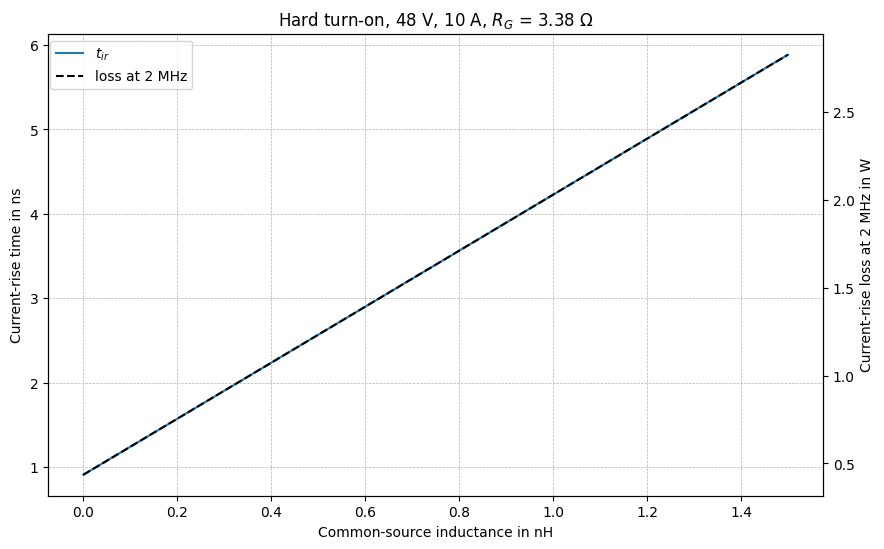

In [4]:
if __name__ == "__main__":
    # Subtask 4.2.3 Current-rise time and loss versus L_CS
    L_CS = np.linspace(0, 1.5e-9, 200)
    t_ir = get_t_ir(R_G, L_CS)
    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.plot(L_CS * 1e9, t_ir * 1e9, label='$t_{ir}$')
    ax1.set_xlabel('Common-source inductance in nH')
    ax1.set_ylabel('Current-rise time in ns')
    ax2 = ax1.twinx()
    ax2.plot(L_CS * 1e9, 0.5 * V_DC * I_L * t_ir * 2e6, 'k--', label='loss at 2 MHz')
    ax2.set_ylabel('Current-rise loss at 2 MHz in W')
    ax1.grid(True, which='both', linestyle='--', linewidth=0.5)
    fig.legend(loc='upper left', bbox_to_anchor=(0.12, 0.88))
    plt.title('Hard turn-on, 48 V, 10 A, $R_G$ = 3.38 $\\Omega$')
    plt.show()


### 4.2.3 Solution

The first-order model gives $t_\mathrm{ir} = 0.91$, $1.90$ and $4.22~\mathrm{ns}$ and $E_\mathrm{ir} = 0.22$, $0.46$ and $1.01~\mu\mathrm{J}$ for $L_\mathrm{CS} = 0$, $0.3$ and $1~\mathrm{nH}$. The simulation with $L_\mathrm{G} = 2~\mathrm{nH}$ gives 13 to 23 % shorter times: when $v_\mathrm{GS}$ passes $V_\mathrm{th}$, the gate current is already flowing in $L_\mathrm{G}$ and the feedback through $L_\mathrm{CS}$ cannot reduce it at once. The trend is the same. $L_\mathrm{CS}$ acts like an extra gate resistance $L_\mathrm{CS} g_\mathrm{m}/C_\mathrm{iss}$ ($12~\Omega$ per nH here); the current-rise loss grows linearly with it, to about $2~\mathrm{W}$ at $2~\mathrm{MHz}$ for $1~\mathrm{nH}$.


## 4.3 False turn-on by the current transfer

The low-side transistor conducts $10~\mathrm{A}$ in reverse; the high-side transistor takes over the current within $t_\mathrm{p} = 1~\mathrm{ns}$. Low-side gate loop: $L_\mathrm{G} = 2~\mathrm{nH}$, $C_\mathrm{GS} = 600~\mathrm{pF}$, resistance $R_\mathrm{off}$, common-source inductance $L_\mathrm{CS} = 0.5~\mathrm{nH}$.

4.3.1 Create the function `get_spike(R_off, t)` which returns $v_\mathrm{GS}(t)$ of the low-side transistor for the source term $-L_\mathrm{CS}\,\mathrm{d}i_\mathrm{D}/\mathrm{d}t$ (pulse starting at $2~\mathrm{ns}$; use `scipy.signal.lsim`). Plot $v_\mathrm{GS}(t)$ for $R_\mathrm{off} = 0$, $0.8$ and $2.5~\Omega$ with $V_\mathrm{th}$.

4.3.2 Compare the amplitude for $R_\mathrm{off} = 0$ with $2 L_\mathrm{CS}\frac{\mathrm{d}i_\mathrm{D}}{\mathrm{d}t}|\sin\frac{\omega_0 t_\mathrm{p}}{2}|$.

4.3.3 Plot the maximum positive gate voltage versus $R_\mathrm{off}$ in the range [$0.2 \ldots 3~\Omega$] and find the smallest $R_\mathrm{off}$ that keeps it below $V_\mathrm{th}/2$.


R_off = 0 Ohm (zeta = 0.00): min -4.41 V, max 4.41 V
R_off = 0.8 Ohm (zeta = 0.22): min -3.26 V, max 1.61 V
R_off = 2.5 Ohm (zeta = 0.68): min -2.05 V, max 0.11 V


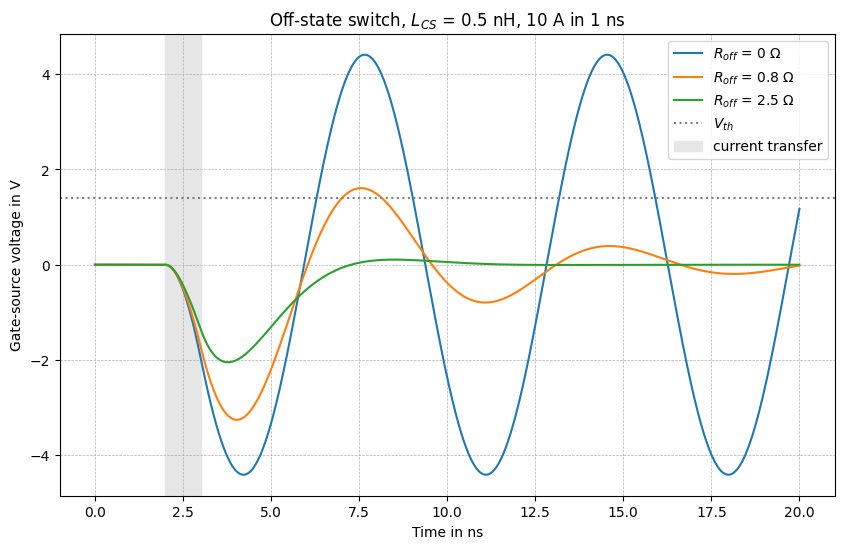

undamped: simulated 4.41 V, formula 4.41 V


smallest R_off with v_max < V_th/2: 1.44 Ohm


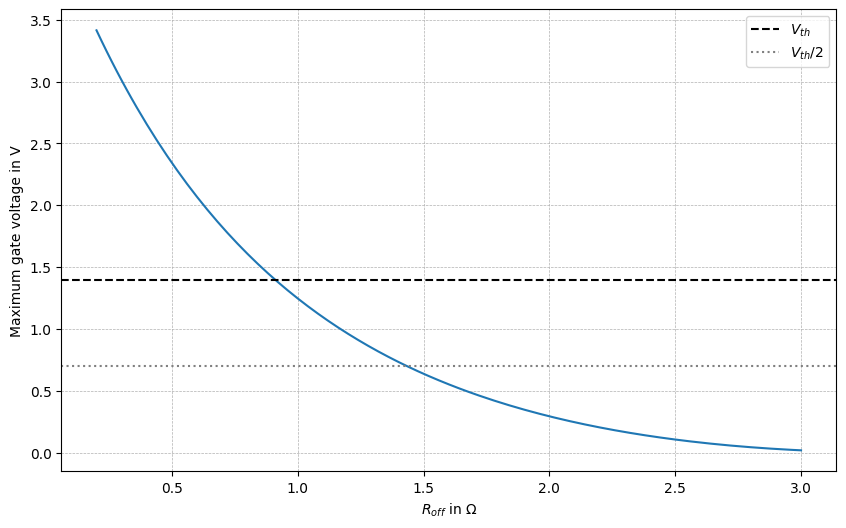

In [5]:
# Subtask 4.3.1 Gate spike of the off-state switch
L_G, C_GS, L_CS_ls, t_p, I_rev = 2e-9, 600e-12, 0.5e-9, 1e-9, 10.0   # Unit H, F, H, s, A
V_s = L_CS_ls * I_rev / t_p                                           # Unit V
omega_0 = 1 / np.sqrt(L_G * C_GS)                                     # Unit 1/s


def get_spike(R_off, t, t_start=2e-9):
    """Gate voltage in V of the off-state switch for the pulse -L_CS di/dt."""
    u = np.where((t >= t_start) & (t < t_start + t_p), -V_s, 0.0)
    _, y, _ = signal.lsim(signal.TransferFunction([1], [L_G * C_GS, R_off * C_GS, 1]), U=u, T=t)
    return y


t = np.linspace(0, 20e-9, 4001)
if __name__ == "__main__":
    plt.figure(figsize=(10, 6))
    for R_off in [0, 0.8, 2.5]:
        v = get_spike(R_off, t)
        print(f"R_off = {R_off} Ohm (zeta = {get_zeta(R_off, L_G, C_GS):.2f}): min {v.min():.2f} V, max {v.max():.2f} V")
        plt.plot(t * 1e9, v, label=f'$R_{{off}}$ = {R_off} $\\Omega$')
    plt.axhline(V_th, color='gray', linestyle=':', label='$V_{th}$')
    plt.axvspan(2, 3, color='0.9', label='current transfer')
    plt.xlabel('Time in ns')
    plt.ylabel('Gate-source voltage in V')
    plt.title('Off-state switch, $L_{CS}$ = 0.5 nH, 10 A in 1 ns')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.show()

    # Subtask 4.3.2 Undamped amplitude
    print(f"undamped: simulated {get_spike(0, t)[t > 3e-9].max():.2f} V, "
          f"formula {2 * V_s * abs(np.sin(omega_0 * t_p / 2)):.2f} V")

    # Subtask 4.3.3 Peak gate voltage versus R_off
    R_range = np.linspace(0.2, 3, 141)
    v_max = np.array([get_spike(R, t).max() for R in R_range])
    print(f"smallest R_off with v_max < V_th/2: {R_range[np.argmax(v_max < V_th / 2)]:.2f} Ohm")
    plt.figure(figsize=(10, 6))
    plt.plot(R_range, v_max)
    plt.axhline(V_th, color='k', linestyle='--', label='$V_{th}$')
    plt.axhline(V_th / 2, color='gray', linestyle=':', label='$V_{th}/2$')
    plt.xlabel('$R_{off}$ in $\\Omega$')
    plt.ylabel('Maximum gate voltage in V')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.show()


### 4.3.3 Solution

The source term is a pulse of $-5~\mathrm{V}$ for $1~\mathrm{ns}$. Without damping the gate oscillates with $4.4~\mathrm{V}$ amplitude after the pulse, as the formula predicts. With $R_\mathrm{off} = 0.8~\Omega$ the gate still reaches $1.6~\mathrm{V} > V_\mathrm{th}$; with $2.5~\Omega$ only $0.1~\mathrm{V}$. About $1.45~\Omega$ keeps the peak below $V_\mathrm{th}/2$. A Kelvin-source connection removes the source term and is the better remedy.


## 4.4 Bootstrap supply

$V_\mathrm{DD} = 5~\mathrm{V}$, $V_\mathrm{F} = 0.5~\mathrm{V}$, $R_\mathrm{boot} = 2~\Omega$, $C_\mathrm{boot} = 100~\mathrm{nF}$, $Q_\mathrm{tot} = 8~\mathrm{nC}$ per period, $V_\mathrm{SD} = 2.5~\mathrm{V}$, $D = 0.25$.

4.4.1 Create the function `get_v_boot(intervals, n_periods)`, which follows $v_\mathrm{boot}$ through a list of intervals (duration, charging target). In each interval the capacitor charges exponentially with $R_\mathrm{boot} C_\mathrm{boot}$ if the target is above $v_\mathrm{boot}$ (the diode blocks otherwise); at the beginning of the high-side on-time $Q_\mathrm{tot}/C_\mathrm{boot}$ is removed. Targets: $V_\mathrm{DD} - V_\mathrm{F}$ while the low-side transistor is on, $V_\mathrm{DD} - V_\mathrm{F} + V_\mathrm{SD}$ while it conducts in reverse.

4.4.2 Plot $v_\mathrm{boot}(t)$ at $3~\mathrm{MHz}$ (dead times $5~\mathrm{ns}$) over 150 periods for (a) ZVS operation, where the low-side transistor conducts in reverse only in the dead time after the high-side turn-off, and (b) hard switching with positive inductor current, where it conducts in reverse in both dead times. Plot (c) $1~\mathrm{MHz}$ without low-side turn-on and $200~\mathrm{ns}$ reverse conduction per period over 20 periods. Print the steady-state voltages at the beginning of the high-side on-time and compare (b) with the charge balance $v_\mathrm{boot} = V_\mathrm{DD} - V_\mathrm{F} + V_\mathrm{SD} - Q_\mathrm{tot} R_\mathrm{boot}/(2 t_\mathrm{d})$.

4.4.3 Plot this voltage versus the reverse-conduction time per period in the range [$5 \ldots 500~\mathrm{ns}$] for case (c) and mark the $6~\mathrm{V}$ limit.


In [6]:
# Subtask 4.4.1 Bootstrap voltage over a sequence of intervals
V_DD, V_F, R_boot, C_boot, Q_tot, V_SD, D = 5.0, 0.5, 2.0, 100e-9, 8e-9, 2.5, 0.25
tau_b = R_boot * C_boot
V_on, V_rc = V_DD - V_F, V_DD - V_F + V_SD   # charging targets in V


def get_v_boot(intervals, n_periods, v0=V_DD - V_F, n_points=20):
    """Follow v_boot through n_periods. intervals: list of (duration, target or None, label);
    the label 'HS' removes Q_tot at the beginning of the high-side on-time.
    Returns time, v_boot and the values at the beginning of each high-side on-time."""
    t_all, v_all, v_hs = [], [], []
    t0, v = 0.0, v0
    for _ in range(n_periods):
        for dur, target, label in intervals:
            if label == 'HS':
                v_hs.append(v)
                v -= Q_tot / C_boot
            tt = np.linspace(0, dur, n_points)
            if target is not None and target > v:
                vv = target - (target - v) * np.exp(-tt / tau_b)
            else:
                vv = np.full_like(tt, v)
            t_all.append(t0 + tt)
            v_all.append(vv)
            t0, v = t0 + dur, vv[-1]
    return np.concatenate(t_all), np.concatenate(v_all), np.array(v_hs)


def get_intervals(f_sw, t_d=5e-9, hard=False):
    """Buck: HS on, dead time with LS reverse conduction, LS on, second dead time.
    hard=True: the LS also conducts in reverse in the second dead time (positive current);
    hard=False (ZVS): the HS conducts in reverse in the second dead time, C_boot is not charged."""
    T = 1 / f_sw
    return [(D * T, None, 'HS'), (t_d, V_rc, 'dt1'), ((1 - D) * T - 2 * t_d, V_on, 'LS'),
            (t_d, V_rc if hard else None, 'dt2')]


def get_intervals_no_ls(f_sw, t_rc):
    """Low-side transistor never turned on: reverse conduction for t_rc, then nothing."""
    T = 1 / f_sw
    return [(D * T, None, 'HS'), (t_rc, V_rc, 'rc'), ((1 - D) * T - t_rc, None, 'idle')]


(a) ZVS, 3 MHz: v_boot at HS turn-on 4.493 V
(b) hard switching, 3 MHz: v_boot at HS turn-on 5.439 V, charge balance 5.40 V
(c) 1 MHz, no LS turn-on, 200 ns reverse conduction: v_boot at HS turn-on 6.953 V


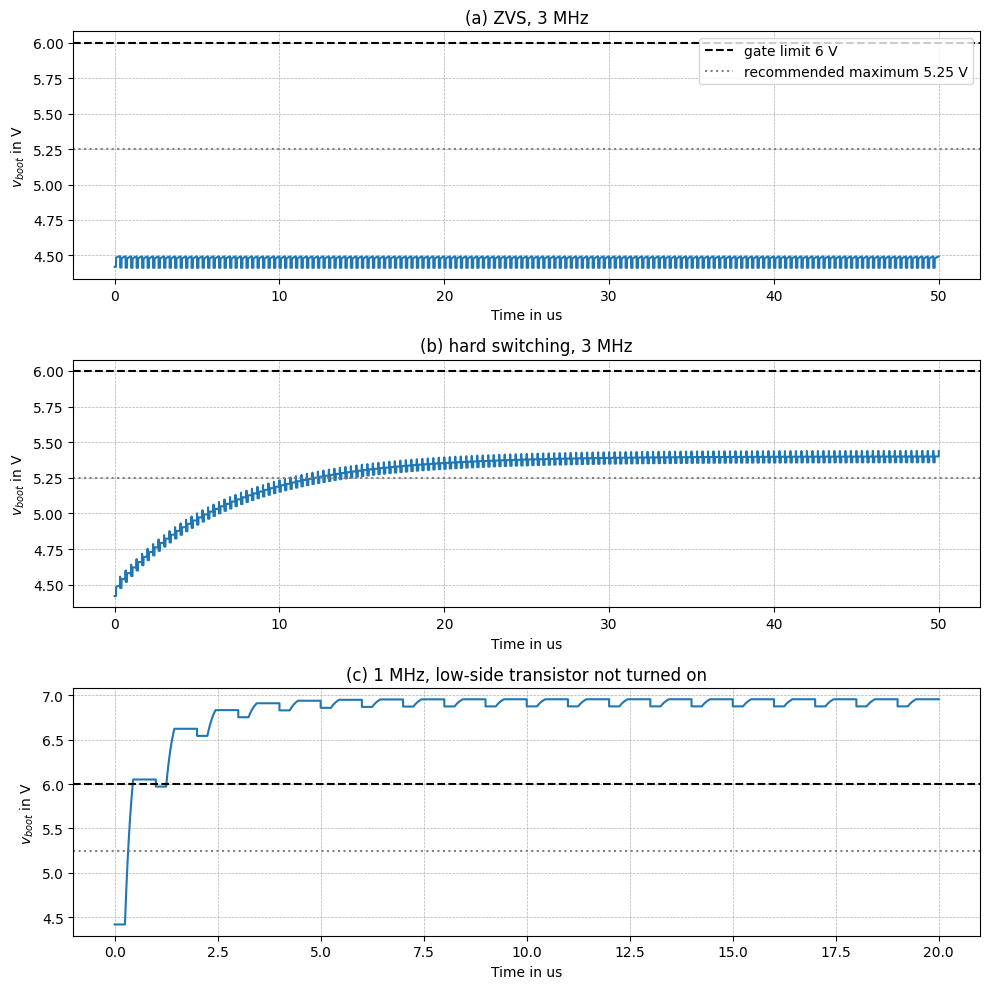

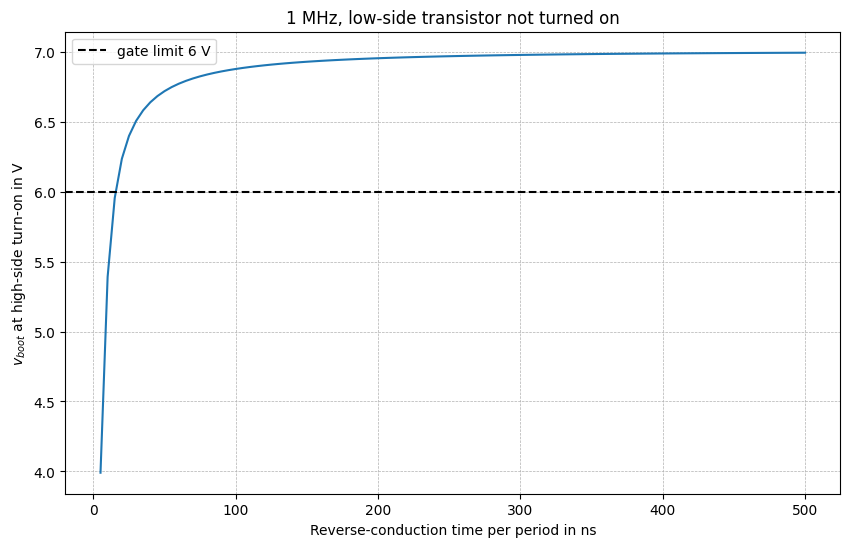

In [7]:
if __name__ == "__main__":
    # Subtask 4.4.2 Bootstrap voltage over many periods
    t_a, v_a, hs_a = get_v_boot(get_intervals(3e6), 150)
    t_b, v_b, hs_b = get_v_boot(get_intervals(3e6, hard=True), 150)
    t_c, v_c, hs_c = get_v_boot(get_intervals_no_ls(1e6, 200e-9), 20)
    print(f"(a) ZVS, 3 MHz: v_boot at HS turn-on {hs_a[-1]:.3f} V")
    print(f"(b) hard switching, 3 MHz: v_boot at HS turn-on {hs_b[-1]:.3f} V, "
          f"charge balance {V_rc - Q_tot * R_boot / (2 * 5e-9):.2f} V")
    print(f"(c) 1 MHz, no LS turn-on, 200 ns reverse conduction: v_boot at HS turn-on {hs_c[-1]:.3f} V")
    fig, axs = plt.subplots(3, 1, figsize=(10, 10))
    for ax, (tt, vv, title) in zip(axs, [(t_a, v_a, '(a) ZVS, 3 MHz'), (t_b, v_b, '(b) hard switching, 3 MHz'),
                                         (t_c, v_c, '(c) 1 MHz, low-side transistor not turned on')]):
        ax.plot(tt * 1e6, vv)
        ax.axhline(6, color='k', linestyle='--', label='gate limit 6 V')
        ax.axhline(5.25, color='gray', linestyle=':', label='recommended maximum 5.25 V')
        ax.set_title(title)
        ax.set_xlabel('Time in us')
        ax.set_ylabel('$v_{boot}$ in V')
        ax.grid(True, which='both', linestyle='--', linewidth=0.5)
    axs[0].legend()
    plt.tight_layout()
    plt.show()

    # Subtask 4.4.3 Steady-state bootstrap voltage versus reverse-conduction time
    t_rc = np.linspace(5e-9, 500e-9, 100)
    v_ss = [get_v_boot(get_intervals_no_ls(1e6, x), 60)[2][-1] for x in t_rc]
    plt.figure(figsize=(10, 6))
    plt.plot(t_rc * 1e9, v_ss)
    plt.axhline(6, color='k', linestyle='--', label='gate limit 6 V')
    plt.xlabel('Reverse-conduction time per period in ns')
    plt.ylabel('$v_{boot}$ at high-side turn-on in V')
    plt.title('1 MHz, low-side transistor not turned on')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.show()


### 4.4.3 Solution

(a) With ZVS the low-side transistor conducts in reverse only before its own on-time; the low-side on-time recharges the capacitor and $v_\mathrm{boot}$ settles at $4.49~\mathrm{V} \approx V_\mathrm{DD} - V_\mathrm{F}$. (b) With reverse conduction in both dead times the diode charges the capacitor towards $7~\mathrm{V}$ twice per period, and only the high-side driver discharges it: $v_\mathrm{boot}$ climbs within about 20 periods to $5.44~\mathrm{V}$ (charge balance $5.4~\mathrm{V}$), above the recommended $5.25~\mathrm{V}$. (c) Without low-side turn-on it reaches $6.95~\mathrm{V}$, above the $6~\mathrm{V}$ limit; already about $15~\mathrm{ns}$ of reverse conduction per period lift it above $6~\mathrm{V}$. A clamp or a synchronous bootstrap switch is required.


## 4.5 Gate-drive power at 13.56 MHz

$Q_\mathrm{G} = 1.5~\mathrm{nC}$ at $5~\mathrm{V}$, $R_\mathrm{G} = 1~\Omega$, $V_\mathrm{th} = 1.4~\mathrm{V}$, resonant inductor with $Q_\mathrm{L} = 50$.

4.5.1 Create the functions `get_P_hard(Q_G, V, f)` and `get_P_res(C, V_a, f, R)` ($\frac{1}{2}(\omega C V_\mathrm{a})^2 R$) and print both at $13.56~\mathrm{MHz}$ for a sinusoid of $5~\mathrm{V}$ peak-to-peak, including the series resistance of the resonant inductor.

4.5.2 Plot $P_\mathrm{hard}$ for $Q_\mathrm{G} = 1.5$ and $7~\mathrm{nC}$ and $P_\mathrm{res}$ for $1.5~\mathrm{nC}$ versus $f_\mathrm{sw}$ in the range [$1 \ldots 30~\mathrm{MHz}$] (log axes).

4.5.3 Plot $v_\mathrm{GS} = V_\mathrm{th} + V_\mathrm{a}\sin\omega t$ for $V_\mathrm{a} = 4.2~\mathrm{V}$ over two periods with $V_\mathrm{th}$, $4~\mathrm{V}$ and the gate limits, and print the fractions of the period with $v_\mathrm{GS} > V_\mathrm{th}$ and $v_\mathrm{GS} > 4~\mathrm{V}$.


In [8]:
# Subtask 4.5.1 Hard-switched and resonant gate drive
f_res, Q_G5, R_G5, Q_L = 13.56e6, 1.5e-9, 1.0, 50
C_eq = Q_G5 / V_dr


def get_P_hard(Q_G, V, f):
    """Gate-drive power in W of a conventional driver."""
    return Q_G * V * f


def get_P_res(C, V_a, f, R):
    """Loss in W of a sinusoidal gate drive with amplitude V_a and series resistance R."""
    return 0.5 * (2 * np.pi * f * C * V_a)**2 * R


L_res = 1 / ((2 * np.pi * f_res)**2 * C_eq)
R_L = 2 * np.pi * f_res * L_res / Q_L
print(f"C_eq = {C_eq*1e12:.0f} pF, L = {L_res*1e9:.0f} nH, R_L = {R_L:.2f} Ohm")
print(f"P_hard = {get_P_hard(Q_G5, V_dr, f_res)*1e3:.1f} mW, "
      f"P_res = {get_P_res(C_eq, 2.5, f_res, R_G5 + R_L)*1e3:.2f} mW")


C_eq = 300 pF, L = 459 nH, R_L = 0.78 Ohm
P_hard = 101.7 mW, P_res = 3.64 mW


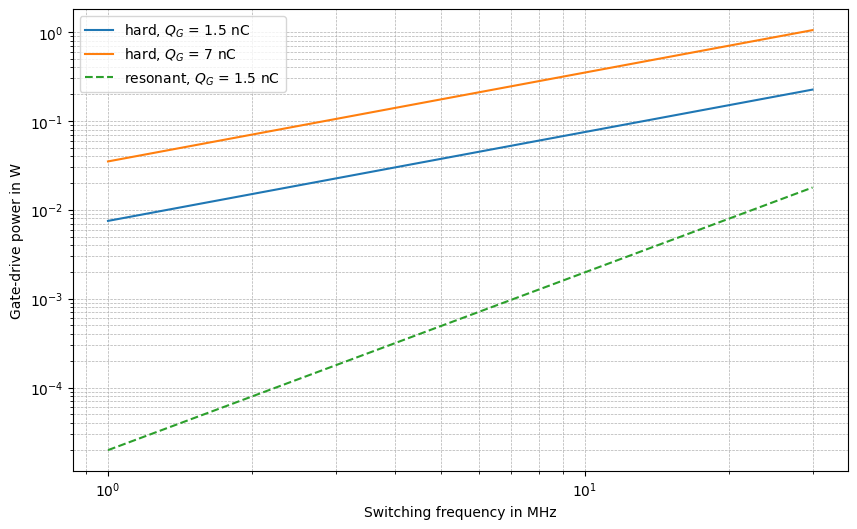

range -2.8 ... 5.6 V, on (v > V_th): 0.50, fully enhanced (v > 4 V): 0.29


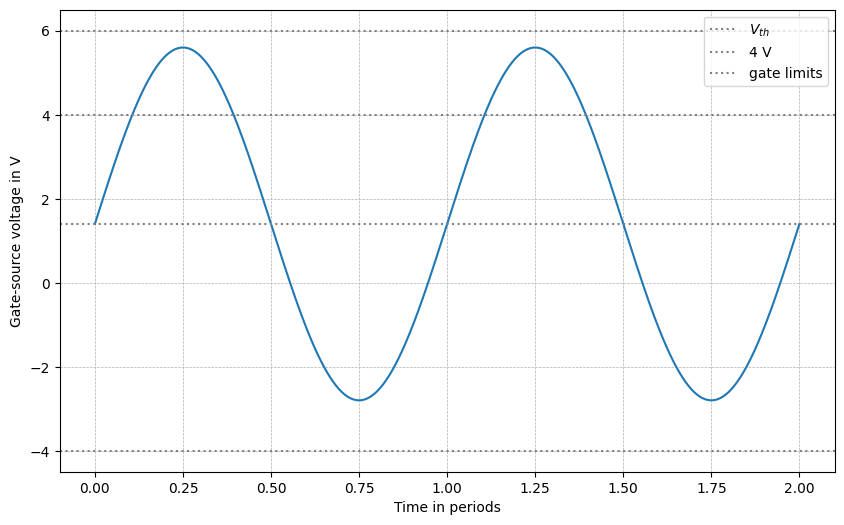

In [9]:
if __name__ == "__main__":
    # Subtask 4.5.2 Gate-drive power versus frequency
    f = np.logspace(6, np.log10(30e6), 200)
    plt.figure(figsize=(10, 6))
    plt.loglog(f / 1e6, get_P_hard(1.5e-9, V_dr, f), label='hard, $Q_G$ = 1.5 nC')
    plt.loglog(f / 1e6, get_P_hard(7e-9, V_dr, f), label='hard, $Q_G$ = 7 nC')
    plt.loglog(f / 1e6, get_P_res(C_eq, 2.5, f, R_G5 + R_L), '--', label='resonant, $Q_G$ = 1.5 nC')
    plt.xlabel('Switching frequency in MHz')
    plt.ylabel('Gate-drive power in W')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.show()

    # Subtask 4.5.3 Sinusoidal gate voltage
    V_a = 4.2
    wt = np.linspace(0, 4 * np.pi, 1000)
    v = V_th + V_a * np.sin(wt)
    print(f"range {v.min():.1f} ... {v.max():.1f} V, on (v > V_th): {np.mean(v > V_th):.2f}, "
          f"fully enhanced (v > 4 V): {np.mean(v > 4):.2f}")
    plt.figure(figsize=(10, 6))
    plt.plot(wt / (2 * np.pi), v)
    for level, text in [(V_th, '$V_{th}$'), (4, '4 V'), (V_GS_max, 'gate limits'), (V_GS_min, None)]:
        plt.axhline(level, color='gray', linestyle=':', label=text)
    plt.xlabel('Time in periods')
    plt.ylabel('Gate-source voltage in V')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)
    plt.legend()
    plt.show()


### 4.5.3 Solution

A conventional driver needs $0.10~\mathrm{W}$ at $13.56~\mathrm{MHz}$ for $1.5~\mathrm{nC}$ and $0.47~\mathrm{W}$ for $7~\mathrm{nC}$. The resonant drive needs a $459~\mathrm{nH}$ inductor ($R_L = 0.78~\Omega$) and loses only $3.6~\mathrm{mW}$. The sinusoidal gate voltage between $-2.8~\mathrm{V}$ and $5.6~\mathrm{V}$ turns the transistor on for 50 % of the period, but it is fully enhanced only for 29 %; the conduction loss is therefore higher than with a rectangular gate voltage.
